Attention : plusieurs correspondances de tailles sont proches. La proposition ci-dessous est a verifier.
Pieces detectees (de la plus petite a la plus grande) :
Taille 1 (rayon 166 px) : 3 piece(s) de 1 TWD = 3 TWD
Taille 2 (rayon 189 px) : 1 piece(s) de 5 TWD = 5 TWD
Taille 3 (rayon 223 px) : 3 piece(s) de 20 TWD = 60 TWD
Taille 4 (rayon 235 px) : 2 piece(s) de 50 TWD = 100 TWD
Erreur moyenne de correspondance des tailles : 1.1%

Total : 168 TWD
Equivalent en EUR : 4.55 EUR
Equivalent en euros : 4.55 EUR
Taux mis a jour le : Thu, 05 Nov 2026 00:02:31 +0000


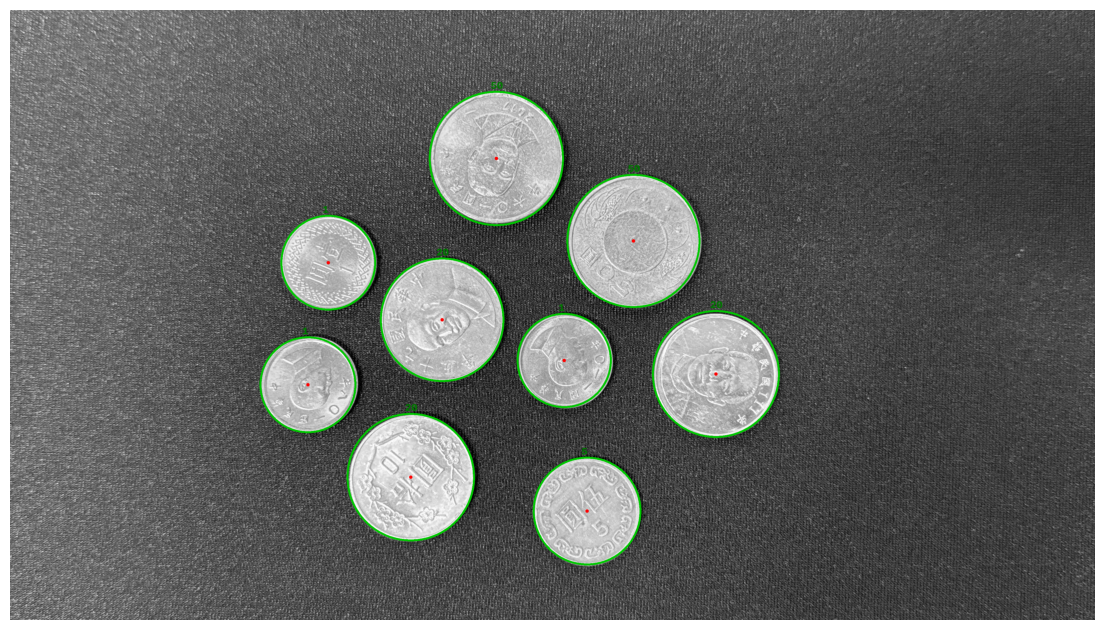

In [13]:
import json
from itertools import combinations
from urllib.request import urlopen

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Photo a analyser. Ajoute la photo dans data/ puis adapte ce chemin.
chemin_image = './data/image3.jpg'

# Devise d'affichage choisie (code ISO : EUR, USD, CAD, etc.).
devise_souhaitee = 'EUR'

# Diametres de reference des pieces courantes (millimetres).
diametres_twd_mm = {1: 20.0, 5: 22.0, 10: 26.0, 20: 26.85, 50: 28.0}

facteur_reduction = 0.25
image_gris = cv2.imread(chemin_image, cv2.IMREAD_GRAYSCALE)
if image_gris is None:
    raise FileNotFoundError(f'Image introuvable : {chemin_image}')

image_reduite = cv2.resize(
    image_gris, None, fx=facteur_reduction, fy=facteur_reduction,
    interpolation=cv2.INTER_AREA
)
image_floue = cv2.medianBlur(image_reduite, 5)
cercles = cv2.HoughCircles(
    image_floue,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=22,
    param1=100,
    param2=40,
    minRadius=35,
    maxRadius=65,
)
if cercles is None:
    raise ValueError('Aucune piece detectee. Essaie une photo nette, prise de dessus.')

cercles = np.round(cercles[0] / facteur_reduction).astype(int)
cercles_par_taille = sorted(cercles, key=lambda cercle: cercle[2])

# Regroupe les rayons proches pour compter plusieurs pieces de meme taille.
groupes = []
for cercle in cercles_par_taille:
    rayon = cercle[2]
    if groupes:
        rayon_median = float(np.median([item[2] for item in groupes[-1]]))
        if abs(rayon - rayon_median) / rayon_median <= 0.04:
            groupes[-1].append(cercle)
            continue
    groupes.append([cercle])


def trouver_correspondance(groupes_mesures, references):
    if len(groupes_mesures) < 2:
        raise ValueError(
            'Il faut au moins deux tailles de pieces differentes pour les identifier '
            'par comparaison. Une seule taille ne donne pas d echelle.'
        )
    if len(groupes_mesures) > len(references):
        raise ValueError('Plus de tailles detectees que de valeurs dans le catalogue.')

    rayons_mesures = np.array([
        np.median([cercle[2] for cercle in groupe]) for groupe in groupes_mesures
    ], dtype=float)
    candidats = []
    for valeurs in combinations(references, len(groupes_mesures)):
        diametres = np.array([references[valeur] for valeur in valeurs], dtype=float)
        echelle = float(np.median(rayons_mesures / diametres))
        rayons_estimes = diametres * echelle
        erreur = float(np.mean(np.abs(rayons_mesures - rayons_estimes) / rayons_estimes))
        candidats.append((erreur, valeurs))

    candidats.sort(key=lambda candidat: candidat[0])
    return rayons_mesures, candidats


rayons_groupes, candidats = trouver_correspondance(groupes, diametres_twd_mm)
meilleure_erreur, valeurs_par_taille = candidats[0]
if meilleure_erreur > 0.08:
    raise ValueError(
        'Les tailles detectees ne correspondent pas assez aux pieces du catalogue. '
        'Essaie une photo prise bien a plat, sans perspective.'
    )
if len(candidats) > 1 and candidats[1][0] - meilleure_erreur < 0.01:
    print(
        'Attention : plusieurs correspondances de tailles sont proches. '
        'La proposition ci-dessous est a verifier.'
    )

# Verification de la fonction sur le cas demande : uniquement 1 et 50 TWD.
groupes_test = [[[0, 0, 20]], [[0, 0, 28]]]
_, candidats_test = trouver_correspondance(groupes_test, diametres_twd_mm)
assert candidats_test[0][1] == (1, 50)

image_resultat = cv2.cvtColor(image_gris, cv2.COLOR_GRAY2RGB)
total_twd = 0
print('Pieces detectees (de la plus petite a la plus grande) :')
for indice, (groupe, valeur_twd) in enumerate(zip(groupes, valeurs_par_taille), start=1):
    total_groupe = len(groupe) * valeur_twd
    total_twd += total_groupe
    rayon_moyen = int(np.median([cercle[2] for cercle in groupe]))
    print(
        f'Taille {indice} (rayon {rayon_moyen} px) : '
        f'{len(groupe)} piece(s) de {valeur_twd} TWD = {total_groupe} TWD'
    )
    for x, y, rayon in groupe:
        cv2.circle(image_resultat, (x, y), rayon, (0, 200, 0), 6)
        cv2.circle(image_resultat, (x, y), 6, (255, 0, 0), -1)
        cv2.putText(
            image_resultat, str(valeur_twd), (x - 20, y - rayon - 10),
            cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 120, 0), 3
        )

print(f'Erreur moyenne de correspondance des tailles : {meilleure_erreur:.1%}')

# Taux du jour : source TWD, avec conversion vers la devise choisie et vers EUR.
url_taux = 'https://open.er-api.com/v6/latest/TWD'
with urlopen(url_taux, timeout=15) as reponse:
    donnees_taux = json.loads(reponse.read().decode('utf-8'))
if donnees_taux.get('result') != 'success':
    raise RuntimeError('Le service de taux de change n a pas renvoye de taux valides.')

taux = donnees_taux['rates']
devise_souhaitee = devise_souhaitee.strip().upper()
if devise_souhaitee not in taux:
    raise ValueError(f'Devise non disponible : {devise_souhaitee}')

montant_devise = total_twd * taux[devise_souhaitee]
montant_eur = total_twd * taux['EUR']
print(f'\nTotal : {total_twd} TWD')
print(f'Equivalent en {devise_souhaitee} : {montant_devise:.2f} {devise_souhaitee}')
print(f'Equivalent en euros : {montant_eur:.2f} EUR')
print(f"Taux mis a jour le : {donnees_taux.get('time_last_update_utc', 'date inconnue')}")

plt.figure(figsize=(14, 8))
plt.imshow(image_resultat)
plt.axis('off')
plt.show()